# ДЗ 2. Прогноз продаж товара

Прогнозируем, сколько декоративных птиц ASSORTED COLOUR BIRD ORNAMENT продаст магазин за день, неделю и месяц. Берём товар 84879 из ДЗ1. Сравним три модели и посмотрим, насколько меняется ошибка, если делать прогноз заранее.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

## Данные из ДЗ1

В файле `data/daily_sales.csv` лежат чистые продажи за каждый полный день. Покупки прибавляем, возвраты вычитаем в день оформления. Списание повреждённого товара исключено. Ноль означает, что за день в выгрузке не зарегистрировали продаж или возвратов этого товара. Крупные заказы оставляем.

Последний полный день — 8 декабря 2011 года. Складываем дневные значения за недели с понедельника по воскресенье и за календарные месяцы. Оставляем только полные периоды. Датой каждой суммы будет последний день периода, когда уже известны все продажи.

In [2]:
def load_series(path):
    daily = pd.read_csv(path, parse_dates=['date']).set_index('date')['sales']
    assert daily.index.is_unique and daily.index.is_monotonic_increasing
    daily = daily.asfreq('D')
    assert daily.notna().all(), 'В дневном ряду есть пропуск'

    weeks = daily.resample('W-SUN')
    weekly = weeks.sum()[weeks.count() == 7]
    months = daily.resample('ME')
    monthly = months.sum()
    monthly = monthly[months.count() == monthly.index.days_in_month]
    return {'День': daily, 'Неделя': weekly, 'Месяц': monthly}

series = load_series('data/daily_sales.csv')
pd.DataFrame([
    [name, len(s), s.index[0].date(), s.index[-1].date()]
    for name, s in series.items()
], columns=['Частота', 'Полных периодов', 'Первая дата', 'Последняя дата'])

,Частота,Полных периодов,Первая дата,Последняя дата
0,День,373,2010-12-01,2011-12-08
1,Неделя,52,2010-12-12,2011-12-04
2,Месяц,12,2010-12-31,2011-11-30


## Как проверяем прогноз

Для проверки берём последние 28 дней, 8 недель и 4 месяца. Внутри каждой частоты все модели прогнозируют одни и те же даты. Горизонт показывает, за сколько шагов до этой даты мы сделали прогноз. Например, для прогноза на 8 декабря с горизонтом 7 дней можно использовать продажи по 1 декабря включительно.

Начинаем обучение с первой даты ряда. Когда переходим к следующей дате прогноза, добавляем в обучение ещё одно известное значение. Это проверка с расширяющимся окном. В таблице показано первое, самое короткое окно обучения для каждой частоты.

In [3]:
horizons = {'День': [1, 7, 31, 61], 'Неделя': [1, 4, 8], 'Месяц': [1, 2]}
test_size = {'День': 28, 'Неделя': 8, 'Месяц': 4}

rows = []
for name, s in series.items():
    n = test_size[name]
    first_train = s.iloc[:len(s) - n - max(horizons[name]) + 1]
    assert len(first_train) > 0 and len(s.iloc[-n:]) == n
    rows.append([name, ', '.join(map(str, horizons[name])), len(first_train),
                 first_train.index[-1].date(), s.index[-n].date(), s.index[-1].date(), n])

pd.DataFrame(rows, columns=['Частота', 'Горизонты', 'Точек обучения', 'Обучение по',
                            'Проверка с', 'Проверка по', 'Дат проверки'])

,Частота,Горизонты,Точек обучения,Обучение по,Проверка с,Проверка по,Дат проверки
0,День,"1, 7, 31, 61",285,2011-09-11,2011-11-11,2011-12-08,28
1,Неделя,"1, 4, 8",37,2011-08-21,2011-10-16,2011-12-04,8
2,Месяц,"1, 2",7,2011-06-30,2011-08-31,2011-11-30,4


## Модели

**Наивный прогноз.** В ДЗ1 был заметен недельный ритм. Для дневного ряда повторяем последнюю известную неделю. Например, прогноз на четверг равен продажам последнего известного четверга. Для недель и месяцев берём последнее известное значение. В данных всего один год, поэтому сравнить продажи с тем же периодом прошлого года почти негде.

**Простое экспоненциальное сглаживание.** После каждого наблюдения обновляем уровень продаж. Коэффициент сглаживания модель подбирает на обучающей части. На все будущие даты прогноз равен последнему сглаженному уровню.

In [4]:
def naive_forecast(train, dates, freq):
    period = 7 if freq == 'День' else 1
    last_period = train.iloc[-period:].to_numpy()
    return np.resize(last_period, len(dates))

def smooth_forecast(train, dates, freq):
    model = SimpleExpSmoothing(train.to_numpy(), initialization_method='estimated')
    return model.fit(method='least_squares').forecast(len(dates))

**Градиентный бустинг.** Для дневного прогноза берём продажи вчера, продажи неделю назад, среднее за прошлую неделю и день недели. Для недельного и месячного прогноза используем последнее значение и среднее двух последних периодов.

Обучаем модель предсказывать один шаг. Если нужен прогноз на несколько шагов, добавляем свой прогноз в конец истории и считаем признаки для следующего шага. Для всех частот берём 50 небольших деревьев глубиной до двух. Настройки одинаковы на всех горизонтах.

In [5]:
def sales_features(past, date, freq):
    if freq == 'День':
        return [past[-1], past[-7], np.mean(past[-7:]), date.dayofweek]
    return [past[-1], np.mean(past[-2:])]

def boost_forecast(train, dates, freq):
    past = train.to_list()
    window = 7 if freq == 'День' else 2
    x = [sales_features(past[i-window:i], train.index[i], freq)
         for i in range(window, len(past))]
    model = GradientBoostingRegressor(n_estimators=50, max_depth=2,
                                      learning_rate=0.05, random_state=42)
    model.fit(x, past[window:])

    predictions = []
    for date in dates:
        features = sales_features(past, date, freq)
        value = model.predict([features])[0]
        past.append(value)
        predictions.append(value)
    return predictions

## Прогнозы

Для каждой тестовой даты отступаем назад на нужное число шагов. Модель получает историю до этой границы и список будущих дат. Из полученного прогноза берём последний шаг. Поэтому ошибка на горизонте 61 показывает, насколько мы ошиблись именно на 61-й день.

In [6]:
models = {'Наивный': naive_forecast, 'Сглаживание': smooth_forecast,
          'Бустинг': boost_forecast}

def check_forecasts(s, freq, steps, n_test):
    rows = []
    for h in steps:
        for i in range(len(s) - n_test, len(s)):
            start = i - h + 1
            train = s.iloc[:start]
            dates = s.index[start:i + 1]
            for name, forecast in models.items():
                prediction = forecast(train, dates, freq)
                rows.append([freq, h, name, train.index[-1], dates[-1],
                             s.iloc[i], prediction[-1]])
    return rows

rows = []
for freq, s in series.items():
    rows.extend(check_forecasts(s, freq, horizons[freq], test_size[freq]))

forecasts = pd.DataFrame(rows, columns=['Частота', 'Горизонт', 'Модель', 'Конец обучения',
                                        'Дата прогноза', 'Факт', 'Прогноз'])
results_dir = Path('results')
results_dir.mkdir(exist_ok=True)
forecasts.to_csv(results_dir / 'forecasts.csv', index=False, encoding='utf-8-sig')
forecasts.head(6).round(1)

,Частота,Горизонт,Модель,Конец обучения,Дата прогноза,Факт,Прогноз
0,День,1,Наивный,2011-11-10,2011-11-11,100,80.0
1,День,1,Сглаживание,2011-11-10,2011-11-11,100,93.4
2,День,1,Бустинг,2011-11-10,2011-11-11,100,114.9
3,День,1,Наивный,2011-11-11,2011-11-12,0,0.0
4,День,1,Сглаживание,2011-11-11,2011-11-12,0,93.5
5,День,1,Бустинг,2011-11-11,2011-11-12,0,36.2


## Оценка качества

Основная метрика — **MAE**. Это средняя абсолютная ошибка в штуках. По ней выбираем лучшую модель для каждой частоты и горизонта. **RMSE** тоже измеряется в штуках, но сильнее реагирует на крупные промахи.

Дневные и месячные суммы различаются по масштабу. Чтобы сравнить относительные ошибки, считаем **WAPE** — сумму абсолютных ошибок делим на сумму фактических продаж по модулю и переводим в проценты. Так в расчёте остаются и дни с нулевыми продажами. Для всех трёх метрик меньшее значение лучше.

In [7]:
def get_scores(group):
    error = group['Факт'] - group['Прогноз']
    mae = error.abs().mean()
    rmse = np.sqrt((error ** 2).mean())
    wape = 100 * error.abs().sum() / group['Факт'].abs().sum()
    return [len(group), mae, rmse, wape]

keys = ['Частота', 'Горизонт', 'Модель']
rows = []
for key, group in forecasts.groupby(keys, sort=False):
    rows.append([*key, *get_scores(group)])

scores = pd.DataFrame(rows, columns=keys + ['Дат проверки', 'MAE, шт.', 'RMSE, шт.', 'WAPE, %'])
scores.to_csv(results_dir / 'metrics.csv', index=False, encoding='utf-8-sig')
scores.round(1)

,Частота,Горизонт,Модель,Дат проверки,"MAE, шт.","RMSE, шт.","WAPE, %"
0,День,1,Наивный,28,140.0,236.3,95.3
1,День,1,Сглаживание,28,100.3,135.4,68.3
2,День,1,Бустинг,28,88.3,126.4,60.1
3,День,7,Наивный,28,140.0,236.3,95.3
4,День,7,Сглаживание,28,101.0,136.0,68.8
5,День,7,Бустинг,28,92.1,129.0,62.7
6,День,31,Наивный,28,115.4,160.1,78.6
7,День,31,Сглаживание,28,101.8,141.8,69.3
8,День,31,Бустинг,28,96.7,136.0,65.8
9,День,61,Наивный,28,129.7,172.6,88.3


## Факт и прогноз

Посмотрим, какой прогноз дала каждая модель в конце обучения, если сразу попросить её предсказать 61 день, 8 недель или 2 месяца. Для каждого графика берём одну дату конца обучения. Все точки справа от вертикальной линии предсказаны в этот день. В таблице метрик выше учтены все даты проверки.

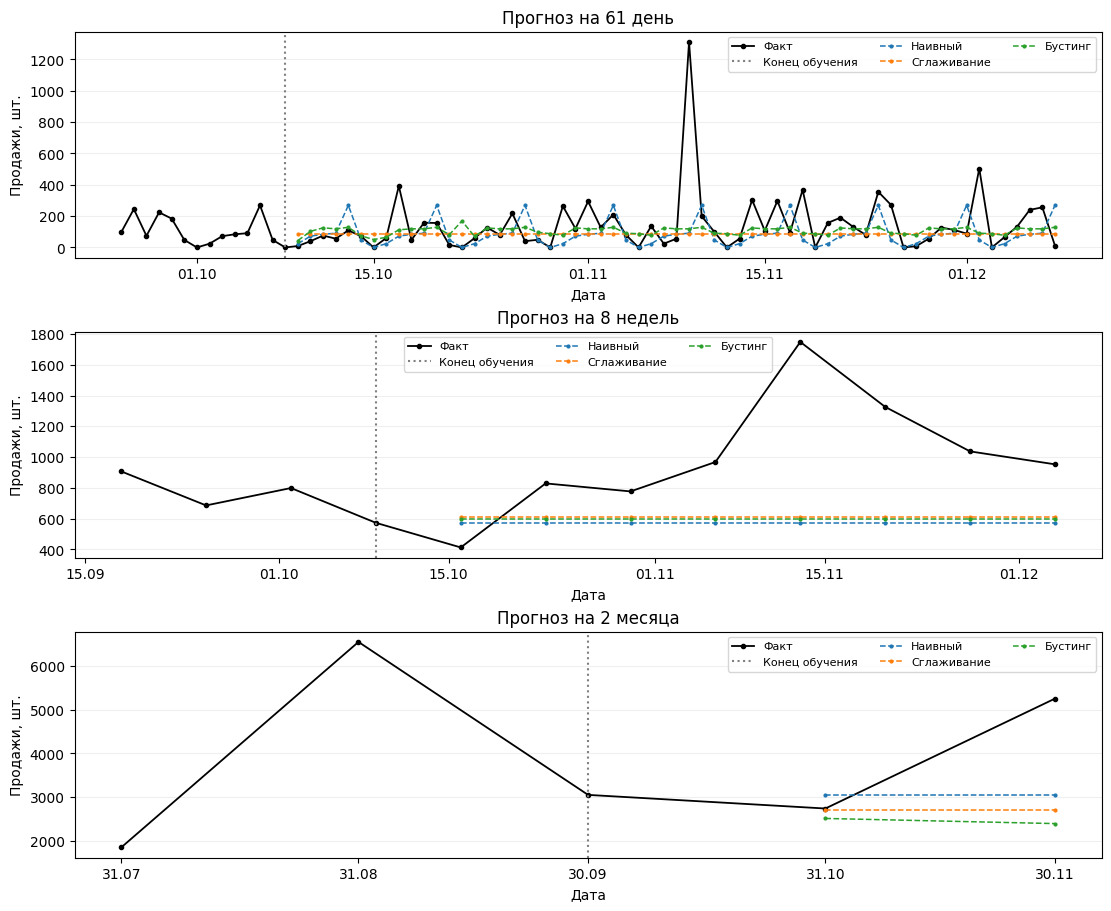

In [8]:
def plot_forecast(ax, s, freq, h, history, title):
    train = s.iloc[:-h]
    test = s.iloc[-h:]
    observed = s.iloc[-(h + history):]
    ax.plot(observed.index, observed, 'o-', color='black', linewidth=1.3,
            markersize=3, label='Факт')
    ax.axvline(train.index[-1], color='gray', linestyle=':', label='Конец обучения')
    for name, forecast in models.items():
        values = forecast(train, test.index, freq)
        ax.plot(test.index, values, '.--', linewidth=1.1, markersize=4, label=name)

    ax.set(title=title, xlabel='Дата', ylabel='Продажи, шт.')
    if freq == 'Месяц':
        ax.set_xticks(observed.index)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
    ax.grid(axis='y', alpha=0.2)
    ax.legend(ncol=3, fontsize=8)

fig, axes = plt.subplots(3, 1, figsize=(11, 9), layout='constrained')
titles = ['Прогноз на 61 день', 'Прогноз на 8 недель', 'Прогноз на 2 месяца']
for ax, (freq, s), history, title in zip(axes, series.items(), [14, 4, 3], titles):
    plot_forecast(ax, s, freq, max(horizons[freq]), history, title)
plt.show()

9 ноября зарегистрировали продажи 1 312 штук. По данным на 8 октября ни одна модель не ожидала такого скачка. Наивный прогноз на этот день дал 91 штуку, сглаживание — 89, бустинг — 119. На недельном графике тот же пик заметен в неделе, которая закончилась 13 ноября.

На месячном графике сглаживание близко к факту в октябре. На ноябрь оно дало тот же прогноз около 2 706 штук, а продажи выросли до 5 254. Модель с постоянным уровнем пропустила этот рост.

## Сравнение по горизонтам

На каждом графике своя шкала продаж. Высота столбца показывает средний промах в штуках за один день, одну неделю или один месяц. Сравниваем модели внутри каждой группы столбцов.

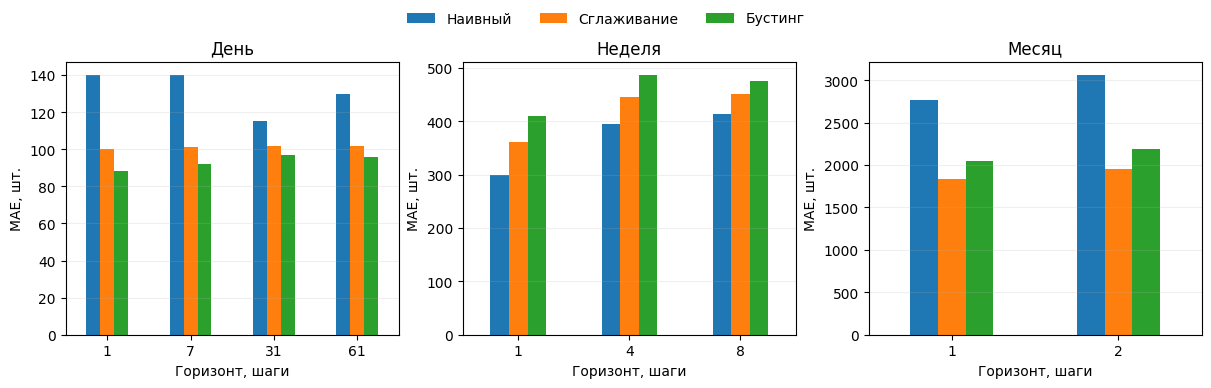

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), layout='constrained')
for ax, freq in zip(axes, series):
    table = scores[scores['Частота'] == freq].pivot(
        index='Горизонт', columns='Модель', values='MAE, шт.')
    table[list(models)].plot.bar(ax=ax, rot=0, legend=False)
    ax.set(title=freq, xlabel='Горизонт, шаги', ylabel='MAE, шт.')
    ax.grid(axis='y', alpha=0.2)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside upper center', ncol=3, frameon=False)
plt.show()

In [10]:
best = scores.loc[scores.groupby(['Частота', 'Горизонт'], sort=False)['MAE, шт.'].idxmin()]
best[['Частота', 'Горизонт', 'Модель', 'MAE, шт.', 'RMSE, шт.', 'WAPE, %']].round(1)

,Частота,Горизонт,Модель,"MAE, шт.","RMSE, шт.","WAPE, %"
2,День,1,Бустинг,88.3,126.4,60.1
5,День,7,Бустинг,92.1,129.0,62.7
8,День,31,Бустинг,96.7,136.0,65.8
11,День,61,Бустинг,96.1,133.4,65.4
12,Неделя,1,Наивный,299.2,373.3,29.7
15,Неделя,4,Наивный,395.1,561.0,39.3
18,Неделя,8,Наивный,413.0,485.3,41.0
22,Месяц,1,Сглаживание,1831.1,2535.5,41.6
25,Месяц,2,Сглаживание,1950.5,2545.4,44.4


## Выводы

**Дни.** Бустинг дал самую низкую MAE на всех четырёх горизонтах. При прогнозе на завтра он ошибался в среднем на 88 штук, на неделю вперёд — на 92. Дальше ошибка выросла до 97 штук на 31-м дне и немного снизилась до 96 на 61-м. У наивной модели результаты на 1 и 7 дней совпали. В обоих случаях для каждой проверочной даты она берёт продажи ровно неделю назад.

**Недели.** На всех трёх горизонтах лучшим по MAE оказалось последнее известное значение. Ошибка выросла с 299 штук на одну неделю до 395 на четыре и 413 на восемь. Если особенно важны крупные промахи, на четырёх неделях лучше сглаживание. Его RMSE равна примерно 543 штукам против 561 у наивного прогноза.

**Месяцы.** По MAE выиграло сглаживание. Ошибка выросла с 1 831 штуки на один месяц до 1 951 на два. Проверяли всего четыре месяца. Среди них август с крупным заказом и ноябрь с ростом продаж. Каждый из этих месяцев заметно влияет на итог, а для обучения бустинга на самом раннем срезе осталось всего пять примеров с известными признаками.

В штуках недельные и месячные ошибки больше дневных, поскольку за период продаётся больше товара. Для лучших моделей на один шаг WAPE составила 60,1% по дням, 29,7% по неделям и 41,6% по месяцам. На этой проверке недельный объём предсказывался точнее в относительном выражении. При сравнении учитываем, что три тестовых отрезка охватывают разные даты.